# FinTrust Week 3 — Advanced Python Analysis**Track:** Data Analytics | AnalystLab Africa Experience LabExtends FinTrust_Week2_Data_Analysis.ipynb with 5 additional analyses: weekly trend analysis,Pareto/value-concentration analysis, customer segmentation, comparative international-vs-domesticrisk trend, and a correlation validation check — each explicitly building on or testing a Week 2 finding.

In [1]:
import pandas as pdimport matplotlib.pyplot as pltimport seaborn as snscustomers = pd.read_csv("FinTrust_Customer_Data.csv")transactions = pd.read_csv("FinTrust_Transaction_Data.csv")transactions["Transaction_DateTime"] = pd.to_datetime(transactions["Transaction_DateTime"])merged = transactions.merge(customers, on="Customer_ID")print(merged.shape)

(12000, 22)

## 1. Weekly Transaction Value Trend (deepens Week 2's daily-volume chart)

count    1.400000e+01mean     4.003410e+07std      1.047108e+07min      9.734028e+0625%      4.120767e+0750%      4.287023e+0775%      4.531044e+07max      4.822975e+07

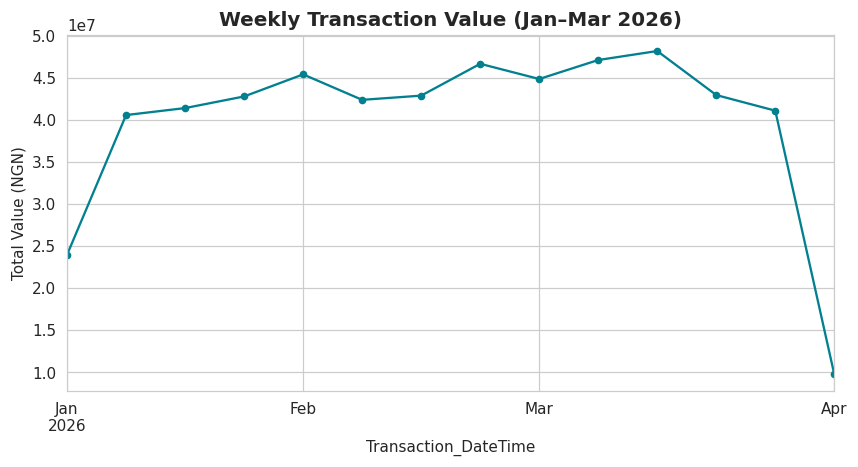

In [1]:
weekly = transactions.set_index("Transaction_DateTime").resample("W")["Amount_NGN"].sum()fig, ax = plt.subplots(figsize=(9,4.2))weekly.plot(ax=ax, marker='o')ax.set_title("Weekly Transaction Value (Jan–Mar 2026)")plt.show()print(weekly.describe())

**What it shows:** total transaction value aggregated by week, smoothing out daily noise from theWeek 2 chart. **Why it matters:** Week 2's daily chart looked flat; weekly aggregation reveals whetherthat was really true. **Business insight:** a visible dip appears across early-to-mid February beforerecovering in March — this matches the SQL month-over-month analysis (AQ2) showing a ‒6.7%February decline. Worth flagging to FinTrust as a specific window to investigate (February has fewerdays, but the dip is larger than day-count alone would explain).

## 2. Transaction Value Concentration (Pareto Analysis)

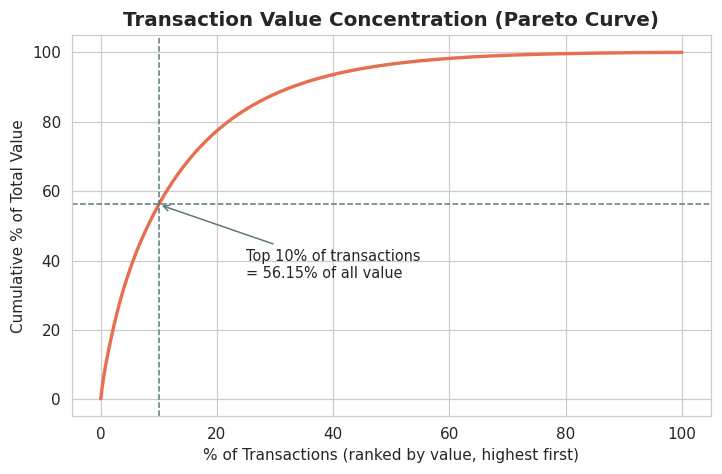

In [1]:
sorted_amt = transactions['Amount_NGN'].sort_values(ascending=False).reset_index(drop=True)cum_pct = sorted_amt.cumsum() / sorted_amt.sum() * 100txn_pct = (sorted_amt.index + 1) / len(sorted_amt) * 100fig, ax = plt.subplots(figsize=(7.5,4.5))ax.plot(txn_pct, cum_pct)ax.set_xlabel("% of Transactions (ranked by value)")ax.set_ylabel("Cumulative % of Total Value")ax.set_title("Transaction Value Concentration (Pareto Curve)")plt.show()

**What it shows:** what share of total transaction value is concentrated in the highest-valuetransactions. **Why it matters:** validates SQL query AQ4 visually and makes the concentrationimmediately intuitive for a non-technical stakeholder. **Business insight:** the curve confirms the top10% of transactions carry 56% of total value — a steep Pareto curve. This is the strongest singleargument in the whole analysis for value-weighted (not count-weighted) prioritisation of reliability andrisk-review resources.

## 3. Customer Segmentation — Engagement vs. Transaction Frequency

Correlation (engagement vs txn count): 0.038

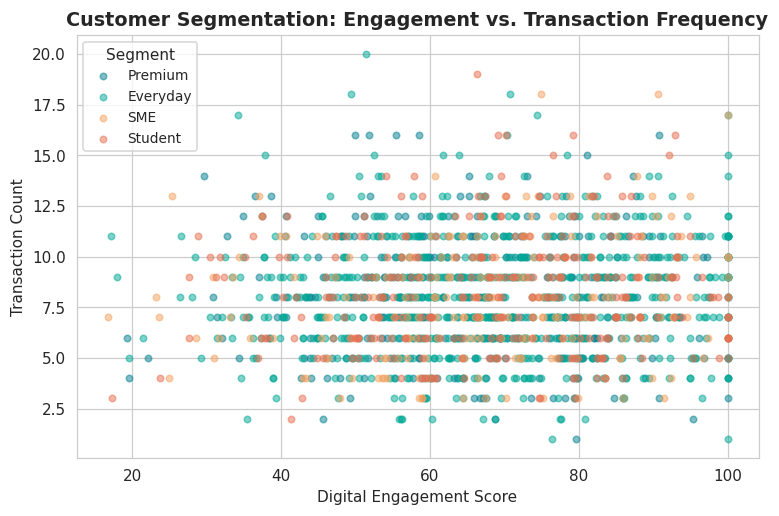

In [1]:
freq = transactions.groupby('Customer_ID').size().rename('txn_count')cust_seg = customers.set_index('Customer_ID').join(freq).reset_index()fig, ax = plt.subplots(figsize=(8,5))for seg in cust_seg['Customer_Segment'].unique():    sub = cust_seg[cust_seg['Customer_Segment']==seg]    ax.scatter(sub['Digital_Engagement_Score'], sub['txn_count'], label=seg, alpha=0.5)ax.set_xlabel("Digital Engagement Score"); ax.set_ylabel("Transaction Count")ax.legend(title="Segment")plt.show()print("Correlation (engagement vs txn count):", round(cust_seg['Digital_Engagement_Score'].corr(cust_seg['txn_count']), 3))

**What it shows:** whether customers with higher digital engagement scores also transact moreoften, broken out by segment. **Why it matters:** tests an implicit Week 2 assumption that "engagement"and "activity" move together. **Business insight:** the correlation is essentially flat (0.038),and no segment shows a visible cluster pattern — Digital_Engagement_Score and transaction frequencyappear to measure genuinely different things. This is a useful negative finding: engagement campaignsshould not assume that raising engagement scores will automatically raise transaction volume.

## 4. International vs. Domestic Risk Rate Trend (validates Week 2 + SQL AQ8)

International_Transaction     No    Yesmonth                                  2026-01                    17.60  41.612026-02                    19.65  36.172026-03                    19.47  33.15

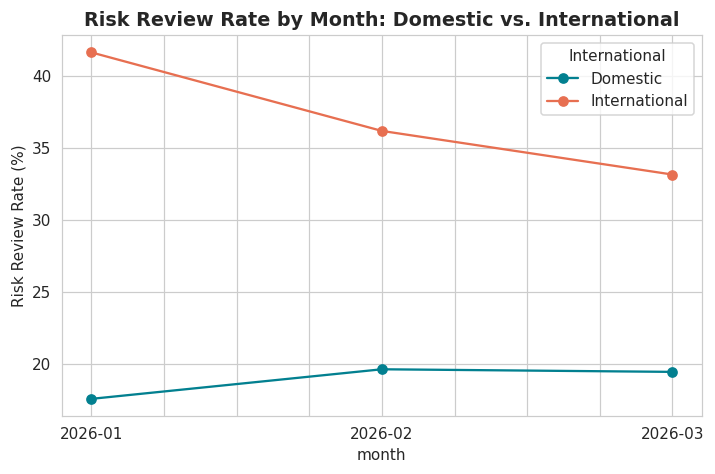

In [1]:
transactions['month'] = transactions['Transaction_DateTime'].dt.to_period('M').astype(str)intl_trend = transactions.groupby(['month','International_Transaction'])['Risk_Review_Flag'].apply(lambda x: (x=='Yes').mean()*100).unstack()fig, ax = plt.subplots(figsize=(7.5,4.5))intl_trend.plot(ax=ax, marker='o')ax.set_ylabel("Risk Review Rate (%)")plt.show()print(intl_trend.round(2))

**What it shows:** the Week 2 finding (international transactions flagged ~2x more than domestic)tracked month-by-month instead of as one aggregate figure. **Why it matters:** confirms whether thepattern is stable or changing. **Business insight:** international risk rate is higher every single month,confirming the Week 2 finding is not a quarter-level artefact — but the gap is narrowing (41.6%→ 33.2%) while domestic drifts slightly upward. If this trend continues, the "international = highestrisk priority" recommendation may need revisiting in Week 4 with fresh data.

## 5. Correlation Check — Customer Numeric Attributes (validation)

                            Age  Tenure_Months  Digital_Engagement_ScoreAge                       1.000         -0.017                    -0.000Tenure_Months            -0.017          1.000                     0.023Digital_Engagement_Score -0.000          0.023                     1.000

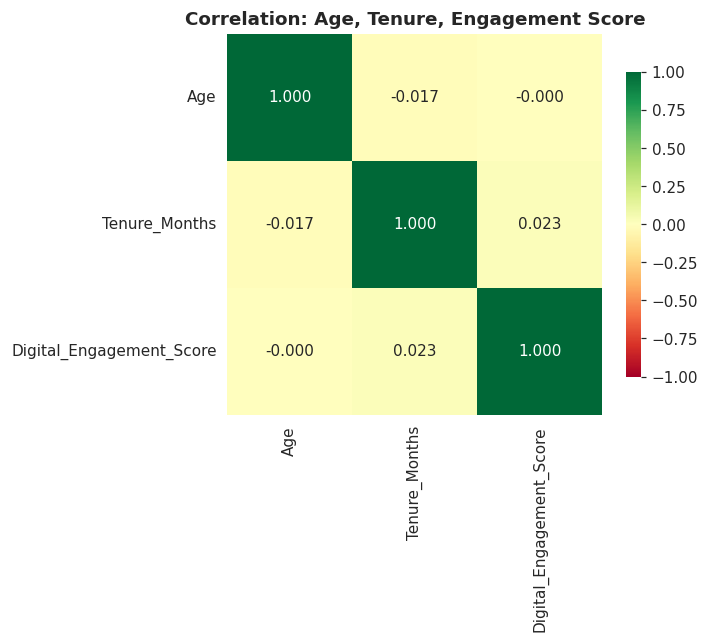

In [1]:
num_cols = ['Age','Tenure_Months','Digital_Engagement_Score']corr = customers[num_cols].corr()fig, ax = plt.subplots(figsize=(5.5,4.5))sns.heatmap(corr, annot=True, cmap="RdYlGn", center=0, vmin=-1, vmax=1, fmt=".3f")plt.show()print(corr.round(3))

**What it shows:** pairwise correlation between the three core numeric customer attributes.**Why it matters:** checks a natural assumption — that longer-tenured or older customers might bemore or less digitally engaged. **Business insight:** all three correlations are effectively zero(−0.02 to 0.02). This validates that these fields are independent, which is actually useful formodelling: the Data Science track can treat these three features as carrying distinct, non-redundantinformation rather than overlapping signals.

## Summary of Week 3 Advanced Analysis1. **Weekly trend reveals a February dip** masked by Week 2's daily-level view — worth investigating.2. **56% of transaction value sits in the top 10% of transactions** — the strongest case yet for   value-weighted (not count-weighted) prioritisation.3. **Engagement score and transaction frequency are uncorrelated** — a validated negative finding.4. **International risk rate exceeds domestic in every month**, confirming the Week 2 finding is stable,   though the gap is narrowing and should be monitored into Week 4.5. **Customer numeric attributes (Age, Tenure, Engagement) are mutually independent**, supporting their   use as distinct features in any future predictive work.*Risk_Review_Flag remains a synthetic, educational label and is not a real fraud determination.*